In [1]:
import os
import sys
from pathlib import Path

# Set project root to sys.path
PROJECT_DIR = str(Path(os.getcwd()).resolve().parent)
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from src.config import MEDIA_FOLDER_PATH, VIDEO_FILE
from src.preprocessor import DataPreprocessor

print(f"Project Directory: {PROJECT_DIR}")
print(f"Media Directory:   {MEDIA_FOLDER_PATH}")
print(f"Video File:        {os.path.join(MEDIA_FOLDER_PATH, VIDEO_FILE)}")
print(f"Video Exists:      {os.path.exists(os.path.join(MEDIA_FOLDER_PATH, VIDEO_FILE))}")

# Initialize preprocessor
preprocessor = DataPreprocessor(media_folder_path=MEDIA_FOLDER_PATH)
print(f"Active Compute Device: {preprocessor.device}")


Project Directory: /Users/ojasvita/Downloads/unmayaverse
Media Directory:   /Users/ojasvita/Downloads/unmayaverse/data
Video File:        /Users/ojasvita/Downloads/unmayaverse/data/unmaya_HD.mp4
Video Exists:      True
Active Compute Device: mps


In [3]:
import glob
from PIL import Image

# 1. Extract frames (720p max width, JPEG quality 3 -> ~30KB/frame)
frames_folder = preprocessor.extract_frames(fps=1)

# 2. Inspect extracted frames
frame_files = sorted(glob.glob(os.path.join(frames_folder, "*.jpg")))
print(f"Total Extracted Frames: {len(frame_files)}")

if frame_files:
    sample_img = Image.open(frame_files[0])
    file_size_kb = os.path.getsize(frame_files[0]) / 1024
    print(f"Sample Frame Size: {sample_img.size} (Width x Height)")
    print(f"Sample File Size: {file_size_kb:.1f} KB")
    
    # # Display preview inline (e.g., frame #26 where Maya appears)
    # preview_idx = min(26, len(frame_files) - 1)
    # display(Image.open(frame_files[preview_idx]))


Extracting encoded 720p frames (q=3) from /Users/ojasvita/Downloads/unmayaverse/data/unmaya_HD.mp4...


ffmpeg version 7.1 Copyright (c) 2000-2024 the FFmpeg developers
  built with Apple clang version 15.0.0 (clang-1500.1.0.2.5)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/7.1 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex --en

[Success] Extracted frames saved to: /Users/ojasvita/Downloads/unmayaverse/data/frames_1fps
Total Extracted Frames: 299
Sample Frame Size: (720, 406) (Width x Height)
Sample File Size: 31.1 KB


[out#0/image2 @ 0xc98824300] video:6450KiB audio:0KiB subtitle:0KiB other streams:0KiB global headers:0KiB muxing overhead: unknown
frame=  299 fps= 27 q=3.0 Lsize=N/A time=00:04:59.00 bitrate=N/A speed=26.5x    


In [ ]:
# Extract master WAV audio
audio_path = preprocessor.extract_master_audio()

if os.path.exists(audio_path):
    size_mb = os.path.getsize(audio_path) / (1024 * 1024)
    print(f"Master audio extracted: {audio_path} ({size_mb:.2f} MB)")


Extracting 48kHz WAV audio to /Users/ojasvita/Downloads/unmayaverse/data/master_audio.wav...


ffmpeg version 7.1 Copyright (c) 2000-2024 the FFmpeg developers
  built with Apple clang version 15.0.0 (clang-1500.1.0.2.5)
  configuration: --prefix=/opt/homebrew/Cellar/ffmpeg/7.1 --enable-shared --enable-pthreads --enable-version3 --cc=clang --host-cflags= --host-ldflags='-Wl,-ld_classic' --enable-ffplay --enable-gnutls --enable-gpl --enable-libaom --enable-libaribb24 --enable-libbluray --enable-libdav1d --enable-libharfbuzz --enable-libjxl --enable-libmp3lame --enable-libopus --enable-librav1e --enable-librist --enable-librubberband --enable-libsnappy --enable-libsrt --enable-libssh --enable-libsvtav1 --enable-libtesseract --enable-libtheora --enable-libvidstab --enable-libvmaf --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx264 --enable-libx265 --enable-libxml2 --enable-libxvid --enable-lzma --enable-libfontconfig --enable-libfreetype --enable-frei0r --enable-libass --enable-libopencore-amrnb --enable-libopencore-amrwb --enable-libopenjpeg --enable-libspeex --en

[Success] Audio extracted to: /Users/ojasvita/Downloads/unmayaverse/data/master_audio.wav
Master audio extracted: /Users/ojasvita/Downloads/unmayaverse/data/master_audio.wav (54.78 MB)


[out#0/wav @ 0x7af004840] video:0KiB audio:56092KiB subtitle:0KiB other streams:0KiB global headers:0KiB muxing overhead: 0.000136%
size=   56092KiB time=00:04:59.15 bitrate=1536.0kbits/s speed= 772x    


In [5]:
# Separate vocals vs instrumental background score
separated_score_path = preprocessor.separate_audio_demucs()

if os.path.exists(separated_score_path):
    print(f"Isolated background score: {separated_score_path}")


Separating audio streams with Demucs (Vocals vs Score/FX)...
Selected model is a bag of 1 models. You will see that many progress bars per track.
Separated tracks will be stored in /Users/ojasvita/Downloads/unmayaverse/data/htdemucs
Separating track /Users/ojasvita/Downloads/unmayaverse/data/master_audio.wav


100%|████████████████████████████████████████████████████████████████████████| 304.2/304.2 [00:24<00:00, 12.61seconds/s]


[Success] Instrumental score isolated at: /Users/ojasvita/Downloads/unmayaverse/data/htdemucs/master_audio/no_vocals.wav
Isolated background score: /Users/ojasvita/Downloads/unmayaverse/data/htdemucs/master_audio/no_vocals.wav


In [17]:
import ssl
import json

# Fix SSL certificate verification for model download
ssl._create_default_https_context = ssl._create_unverified_context

# Run Whisper transcription ('base' or 'medium')
transcript_json = preprocessor.transcribe_audio_whisper(model_name="medium")

# Preview the dialogue mapping
with open(transcript_json, "r") as f:
    transcripts = json.load(f)

print(f"Total timestamped seconds with dialogue: {len(transcripts)}")
for sec in list(transcripts.keys())[:5]:
    print(f"Second {sec}s: \"{transcripts[sec]}\"")


Transcribing audio with Whisper (medium)...


/Users/ojasvita/Downloads/unmayaverse/.venv/lib/python3.10/site-packages/whisper/__init__.py:69: UserWarning: /Users/ojasvita/.cache/whisper/medium.pt exists, but the SHA256 checksum does not match; re-downloading the file
  warnings.warn(
100%|█████████████████████████████████████| 1.42G/1.42G [03:43<00:00, 6.83MiB/s]
/Users/ojasvita/Downloads/unmayaverse/.venv/lib/python3.10/site-packages/whisper/transcribe.py:132: UserWarning: FP16 is not supported on CPU; using FP32 instead
  warnings.warn("FP16 is not supported on CPU; using FP32 instead")


[Success] Saved transcript mapping to: /Users/ojasvita/Downloads/unmayaverse/data/unmaya_semantic_transcripts.json
Total timestamped seconds with dialogue: 208
Second 0s: "I"
Second 1s: "I"
Second 2s: "I"
Second 3s: "I"
Second 4s: "I"


download_path: /Users/ojasvita/.insightface/models/buffalo_l


100%|██████████| 281857/281857 [00:40<00:00, 6897.30KB/s]


[Success] Extracted Maya reference face vector from frame #26
Maya face vector shape: (512,)


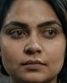

Matching Maya faces: 100%|██████████| 299/299 [01:23<00:00,  3.60it/s]


[Success] Detected 176 faces across frames. Matched Maya in 138 instances.
Detected Maya in 138 unique frames!


In [14]:
# 1. Extract Maya's 512d face vector from reference frame #26
maya_emb = preprocessor.extract_maya_reference_embedding(reference_input=26)
print(f"Maya face vector shape: {maya_emb.shape}")

# Preview the saved face crop preview
crop_path = os.path.join(MEDIA_FOLDER_PATH, "maya_reference_crop.jpg")
if os.path.exists(crop_path):
    display(Image.open(crop_path))

# 2. Match Maya across all frames using cosine similarity threshold 0.35
face_matches = preprocessor.run_face_analysis(similarity_threshold=0.35)
maya_frames = [f["frame_index"] for f in face_matches if f.get("character") == "Maya"]
print(f"Detected Maya in {len(set(maya_frames))} unique frames!")


In [26]:
# Create unified metadata payload (frame_index, timestamp, transcript, characters)
aligned_items = preprocessor.extract_and_align_all_raw_data()

print(f"Total aligned frames: {len(aligned_items)}")
# Preview frame with detected characters or dialogue
sample = next((item for item in aligned_items if item["characters"]), aligned_items[0])
print(json.dumps(sample, indent=2))


[Success] Aligned raw metadata for 299 frames into /Users/ojasvita/Downloads/unmayaverse/data/unmaya_frame_metadata.json
Total aligned frames: 299
{
  "frame_index": 14,
  "timestamp": 14,
  "file_path": "/Users/ojasvita/Downloads/unmayaverse/data/frames_1fps/frame_0015.jpg",
  "text": "I",
  "characters": [
    "Maya"
  ]
}


In [6]:
from src.embedder import MultimodalEmbedder

embedder = MultimodalEmbedder()

img_embs, txt_embs, aud_embs = embedder.run_pipeline(save_to_qdrant=True)

STARTING MULTIMODAL EMBEDDING PIPELINE FOR 299 FRAMES

[1/4] Visual Encoding: Loading SigLIP (google/siglip-so400m-patch14-384) on mps...


Batches:   0%|          | 0/19 [00:05<?, ?it/s]


KeyboardInterrupt: 

In [ ]:
from src.config import MEDIA_FOLDER_PATH
from src.search_engine import MultimodalSearchEngine
from src.gradio_app import build_gradio_ui

engine = MultimodalSearchEngine()
demo = build_gradio_ui(engine)
demo.launch(
    inline=True,
    share=False,
    allowed_paths=[MEDIA_FOLDER_PATH]
)

/Users/ojasvita/Downloads/unmayaverse/.venv/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


Loading Visual Encoder (google/siglip-so400m-patch14-384)...


[transformers] Model config: bos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49406. This may result in unexpected behavior.
[transformers] Model config: eos_token_id must be `None` or an integer within the vocabulary (between 0 and 31999), got 49407. This may result in unexpected behavior.
Loading weights: 100%|██████████| 888/888 [00:00<00:00, 5815.54it/s]


Loading Semantic Encoder (BAAI/bge-large-en-v1.5)...


Loading weights: 100%|██████████| 391/391 [00:00<00:00, 4632.43it/s]


Loading Acoustic Encoder (laion/clap-htsat-unfused)...


Loading weights: 100%|██████████| 447/447 [00:00<00:00, 20680.97it/s]


In [4]:
demo.close()

Closing server running on port: 7860


In [6]:
import json
from src.config import MEDIA_FOLDER_PATH, GOLDEN_DATASET_FILE
from src.search_engine import MultimodalSearchEngine
from src.evaluate import run_benchmark_comparison

# Load dataset
with open(f"{MEDIA_FOLDER_PATH}/{GOLDEN_DATASET_FILE}", "r") as f:
    dataset = json.load(f)

# Initialize search engine and run benchmark across all modes
comparison = run_benchmark_comparison(engine, dataset, min_z_score=1.8)


 UNMAYAVERSE MULTIMODAL RETRIEVAL BENCHMARK EVALUATION
 Dataset Size: 16 queries | Min Z-Score Threshold: 1.8

[Evaluating Mode: visual]...

[Evaluating Mode: visual+text]...

[Evaluating Mode: visual+text+audio]...

Mode                       | MRR     | R@1     | R@3     | R@5     | R@10    | Rejection 
------------------------------------------------------------------------------------------
visual                     | 0.0000  | 0.0000  | 0.0000  | 0.0000  | 0.0000  |  100.0%
visual+text                | 0.0000  | 0.0000  | 0.0000  | 0.0000  | 0.0000  |  100.0%
visual+text+audio          | 0.0000  | 0.0000  | 0.0000  | 0.0000  | 0.0000  |  100.0%

Modality Target Breakdown for 'visual+text+audio':
------------------------------------------------------------
Target Modality      | Queries  | MRR      | Recall@5
------------------------------------------------------------
Visual               | 6        | 0.0000   | 0.0000  
Semantic             | 5        | 0.0000   | 0.0000  
Multi